# Cross-Platform E-Commerce Operations & Demand Analytics

Looking at delivery data from Blinkit, JioMart and Swiggy Instamart to understand order patterns, forecast demand and figure out inventory numbers (EOQ, safety stock, reorder point). Also doing a quick ABC analysis on the product categories.

Dataset: ~105K delivery records (Order ID, Customer ID, Platform, Order Date & Time, Delivery Time, Product Category, Order Value, Customer Feedback, Service Rating, Delivery Delay, Refund Requested), loaded from `ecommerce_delivery_data.csv`.

## 1. Importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

np.random.seed(42)

## 2. Loading the data

Reading the raw export directly from CSV (`ecommerce_delivery_data.csv`) - Order ID, Customer ID, Platform, Order Date & Time, Delivery Time, Product Category, Order Value, Customer Feedback, Service Rating, Delivery Delay, Refund Requested.

In [2]:
df = pd.read_csv('ecommerce_delivery_data.csv', parse_dates=['Order Date & Time'])
df.head()

,Order ID,Customer ID,Platform,Order Date & Time,Delivery Time (Minutes),Product Category,Order Value (INR),Service Rating,Customer Feedback,Delivery Delay,Refund Requested
0,ORD100000,CUST1860,Blinkit,2024-03-23 15:10:00,49,Beauty,2036,3,Average experience,Yes,No
1,ORD100001,CUST4772,Swiggy Instamart,2024-06-17 20:05:00,59,Beauty,612,5,Quick and reliable!,Yes,No
2,ORD100002,CUST4092,Blinkit,2024-02-29 11:57:00,36,Beverages,2012,2,Damaged product received,Yes,Yes
3,ORD100003,CUST1466,JioMart,2024-01-07 21:15:00,10,Beverages,1527,5,"Fast delivery, great service",No,No
4,ORD100004,CUST5426,Swiggy Instamart,2024-04-26 11:12:00,10,Frozen Food,924,3,Average experience,No,No


In [3]:
df.shape

(105000, 11)

## 3. Data cleaning & preprocessing

Standard checks - nulls, duplicates, data types. Also pulling out date/hour/weekday from the timestamp since we'll need those for the demand forecasting part.

In [4]:
df.isnull().sum()

Order ID                   0
Customer ID                0
Platform                   0
Order Date & Time          0
Delivery Time (Minutes)    0
Product Category           0
Order Value (INR)          0
Service Rating             0
Customer Feedback          0
Delivery Delay             0
Refund Requested           0
dtype: int64

In [5]:
df.duplicated(subset='Order ID').sum()

np.int64(0)

In [6]:
df['Order Date & Time'] = pd.to_datetime(df['Order Date & Time'])
df['Order Date'] = df['Order Date & Time'].dt.date
df['Order Hour'] = df['Order Date & Time'].dt.hour
df['Order Weekday'] = df['Order Date & Time'].dt.day_name()

df['Order Date'] = pd.to_datetime(df['Order Date'])
df.dtypes

Order ID                              str
Customer ID                           str
Platform                              str
Order Date & Time          datetime64[us]
Delivery Time (Minutes)             int64
Product Category                      str
Order Value (INR)                   int64
Service Rating                      int64
Customer Feedback                     str
Delivery Delay                        str
Refund Requested                      str
Order Date                  datetime64[s]
Order Hour                          int32
Order Weekday                         str
dtype: object

## 4. Exploratory data analysis

Quick look at how orders split across platforms, categories, ratings and delivery delays before getting into the forecasting/inventory part.

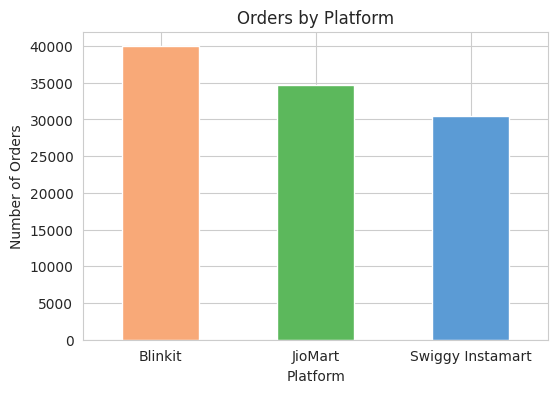

In [7]:
plt.figure(figsize=(6,4))
df['Platform'].value_counts().plot(kind='bar', color=['#f8a978','#5cb85c','#5b9bd5'])
plt.title('Orders by Platform')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.show()

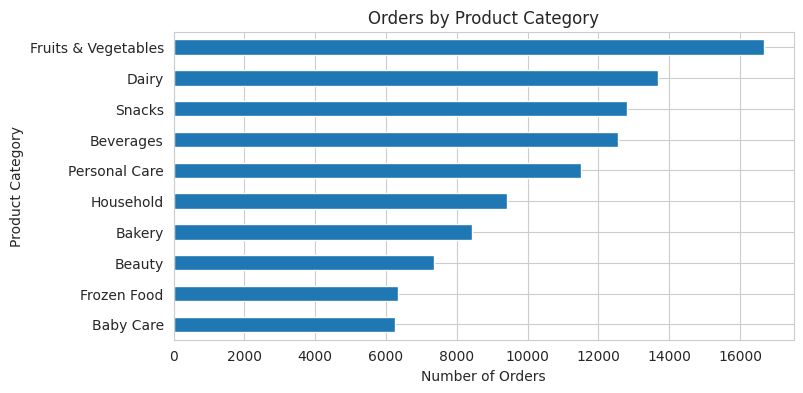

In [8]:
plt.figure(figsize=(8,4))
df['Product Category'].value_counts().plot(kind='barh')
plt.title('Orders by Product Category')
plt.xlabel('Number of Orders')
plt.gca().invert_yaxis()
plt.show()

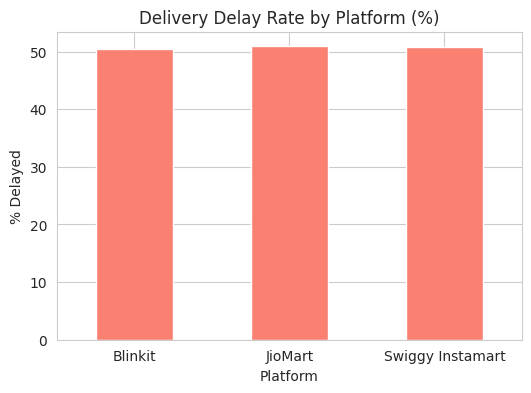

In [9]:
delay_rate = df.groupby('Platform')['Delivery Delay'].apply(lambda x: (x=='Yes').mean()*100)
delay_rate.plot(kind='bar', color='salmon', figsize=(6,4))
plt.title('Delivery Delay Rate by Platform (%)')
plt.ylabel('% Delayed')
plt.xticks(rotation=0)
plt.show()

In [10]:
refund_rate = df.groupby('Product Category')['Refund Requested'].apply(lambda x: (x=='Yes').mean()*100).sort_values(ascending=False)
refund_rate

Product Category
Baby Care              8.273439
Beauty                 8.210984
Beverages              7.990431
Bakery                 7.985782
Frozen Food            7.678938
Snacks                 7.667083
Fruits & Vegetables    7.664628
Dairy                  7.592715
Household              7.517520
Personal Care          7.232896
Name: Refund Requested, dtype: float64

/tmp/ipykernel_585/2813156455.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Service Rating', data=df, palette='viridis')


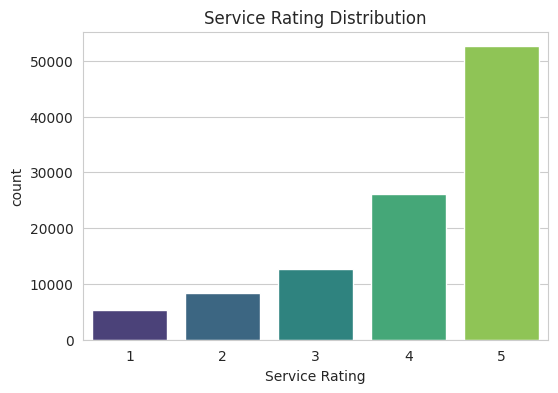

In [11]:
plt.figure(figsize=(6,4))
sns.countplot(x='Service Rating', data=df, palette='viridis')
plt.title('Service Rating Distribution')
plt.show()

## 5. Demand forecasting with ARIMA

Building a daily order-volume series (across all platforms) and fitting an ARIMA model to forecast the next couple of weeks of demand. This is the number that'll feed into the EOQ / reorder point calculations later.

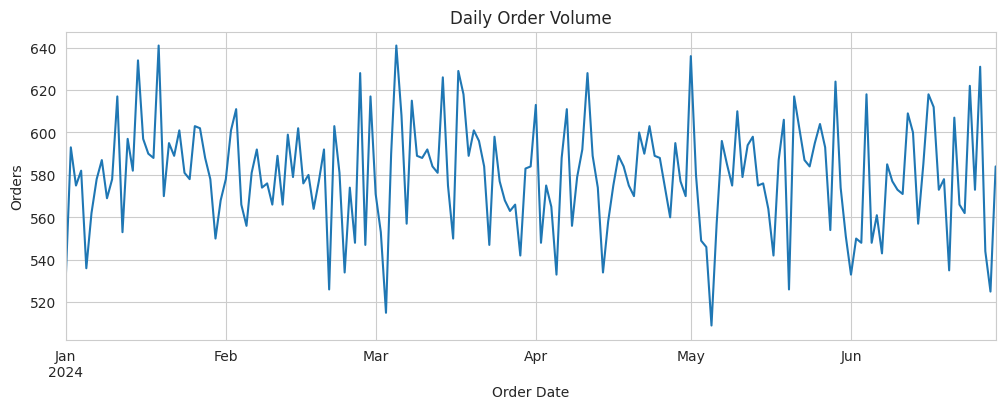

In [12]:
daily_orders = df.groupby('Order Date').size()
daily_orders = daily_orders.asfreq('D').ffill()

plt.figure(figsize=(12,4))
daily_orders.plot()
plt.title('Daily Order Volume')
plt.ylabel('Orders')
plt.show()

In [13]:
train_size = int(len(daily_orders) * 0.9)
train, test = daily_orders[:train_size], daily_orders[train_size:]
len(train), len(test)

(162, 19)

In [14]:
# went with (2,1,2) after eyeballing the ACF/PACF plots - nothing fancy, this data is fairly noisy
model = ARIMA(train, order=(2,1,2))
model_fit = model.fit()
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  162
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -749.084
Date:                Wed, 19 Aug 2026   AIC                           1508.168
Time:                        05:02:35   BIC                           1523.575
Sample:                    01-01-2024   HQIC                          1514.424
                         - 06-10-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9062      0.092     -9.832      0.000      -1.087      -0.726
ar.L2          0.0848      0.089      0.954      0.340      -0.089       0.259
ma.L1         -0.0253      1.374     -0.018      0.9

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


In [15]:
forecast = model_fit.forecast(steps=len(test))
forecast.index = test.index

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))
print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')

MAE: 24.81
RMSE: 29.68


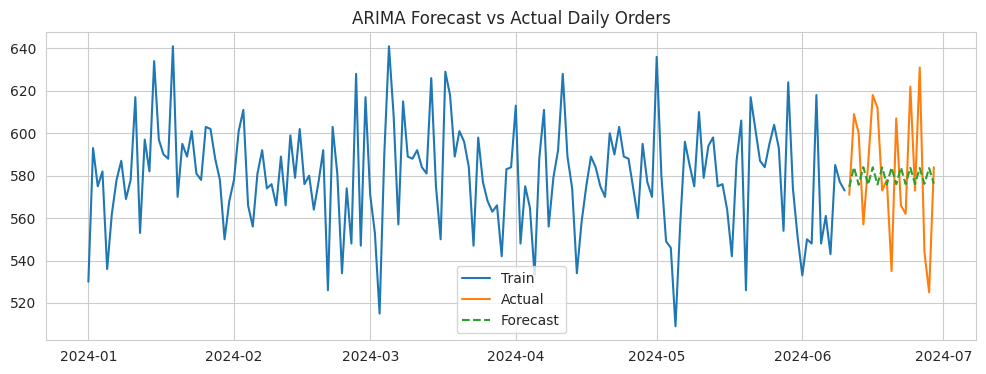

In [16]:
plt.figure(figsize=(12,4))
plt.plot(train.index, train, label='Train')
plt.plot(test.index, test, label='Actual')
plt.plot(forecast.index, forecast, label='Forecast', linestyle='--')
plt.legend()
plt.title('ARIMA Forecast vs Actual Daily Orders')
plt.show()

In [17]:
# refit on full data and forecast the next 14 days - this is what we'll actually use for planning
final_model = ARIMA(daily_orders, order=(2,1,2)).fit()
future_forecast = final_model.forecast(steps=14)
future_forecast

2024-06-30    583.148510
2024-07-01    577.391730
2024-07-02    582.846908
2024-07-03    577.379235
2024-07-04    582.845125
2024-07-05    577.380369
2024-07-06    582.843962
2024-07-07    577.381530
2024-07-08    582.842801
2024-07-09    577.382691
2024-07-10    582.841641
2024-07-11    577.383851
2024-07-12    582.840481
2024-07-13    577.385010
Freq: D, Name: predicted_mean, dtype: float64

## 6. Inventory optimization – EOQ, Safety Stock & Reorder Point

Using the forecasted daily demand along with some reasonable assumptions for ordering cost, holding cost and lead time to work out how much to order and when, per product category.

Assumptions used (feel free to change based on actual finance numbers):
- Ordering cost per order: ₹150
- Holding cost: 15% of unit value per year
- Lead time: 2 days
- Service level: 95% (z = 1.65)

In [18]:
ordering_cost = 150
holding_cost_pct = 0.15
lead_time_days = 2
z_score = 1.65  # 95% service level

category_summary = df.groupby('Product Category').agg(
    total_orders=('Order ID', 'count'),
    avg_order_value=('Order Value (INR)', 'mean')
).reset_index()

# scaling up from our sample window (~6 months) to an annual demand figure
sample_days = (df['Order Date'].max() - df['Order Date'].min()).days
category_summary['annual_demand'] = (category_summary['total_orders'] / sample_days) * 365

category_summary

,Product Category,total_orders,avg_order_value,annual_demand
0,Baby Care,6261,1156.549593,12695.916667
1,Bakery,8440,1168.441943,17114.444444
2,Beauty,7356,1161.412452,14916.333333
3,Beverages,12540,1163.381738,25428.333333
4,Dairy,13671,1161.960793,27721.750000
5,Frozen Food,6329,1163.710065,12833.805556
6,Fruits & Vegetables,16674,1165.196893,33811.166667
7,Household,9418,1163.605118,19097.611111
8,Personal Care,11503,1165.543597,23325.527778
9,Snacks,12808,1158.556449,25971.777778


In [19]:
def calc_eoq(annual_demand, order_cost, holding_cost):
    return np.sqrt((2 * annual_demand * order_cost) / holding_cost)

category_summary['holding_cost_per_unit'] = category_summary['avg_order_value'] * holding_cost_pct
category_summary['EOQ'] = category_summary.apply(
    lambda r: calc_eoq(r['annual_demand'], ordering_cost, r['holding_cost_per_unit']), axis=1)

category_summary[['Product Category', 'annual_demand', 'EOQ']]

,Product Category,annual_demand,EOQ
0,Baby Care,12695.916667,148.171576
1,Bakery,17114.444444,171.156277
2,Beauty,14916.333333,160.270207
3,Beverages,25428.333333,209.080160
4,Dairy,27721.750000,218.438699
5,Frozen Food,12833.805556,148.515004
6,Fruits & Vegetables,33811.166667,240.904780
7,Household,19097.611111,181.176435
8,Personal Care,23325.527778,200.062861
9,Snacks,25971.777778,211.742110


In [20]:
# daily demand + variability per category, needed for safety stock
daily_cat_demand = df.groupby(['Order Date', 'Product Category']).size().unstack(fill_value=0)

demand_std = daily_cat_demand.std()
avg_daily_demand = daily_cat_demand.mean()

category_summary = category_summary.merge(
    avg_daily_demand.rename('avg_daily_demand'), left_on='Product Category', right_index=True)
category_summary = category_summary.merge(
    demand_std.rename('demand_std'), left_on='Product Category', right_index=True)

category_summary['Safety_Stock'] = z_score * category_summary['demand_std'] * np.sqrt(lead_time_days)
category_summary['Reorder_Point'] = (category_summary['avg_daily_demand'] * lead_time_days) + category_summary['Safety_Stock']

category_summary[['Product Category', 'EOQ', 'Safety_Stock', 'Reorder_Point']].round(1)

,Product Category,EOQ,Safety_Stock,Reorder_Point
0,Baby Care,148.2,14.0,83.2
1,Bakery,171.2,16.6,109.9
2,Beauty,160.3,14.1,95.4
3,Beverages,209.1,20.0,158.6
4,Dairy,218.4,18.2,169.3
5,Frozen Food,148.5,14.0,84.0
6,Fruits & Vegetables,240.9,23.3,207.5
7,Household,181.2,17.6,121.6
8,Personal Care,200.1,18.1,145.2
9,Snacks,211.7,19.1,160.6


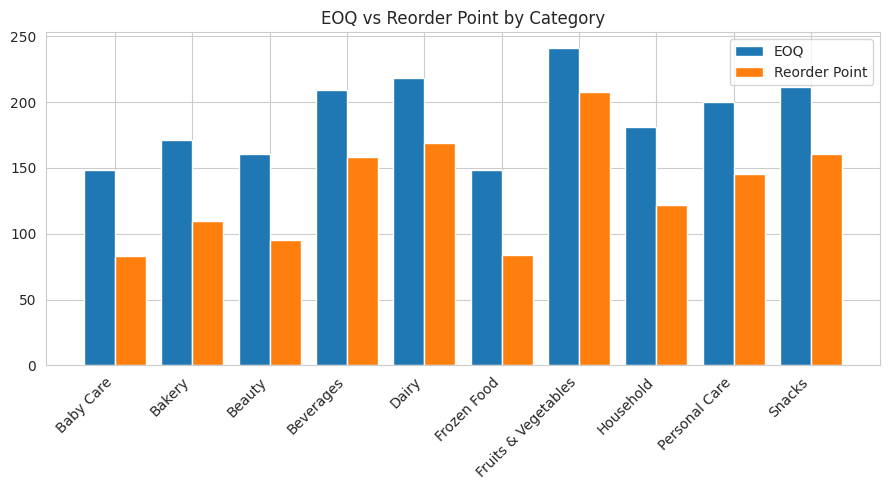

In [21]:
fig, ax = plt.subplots(figsize=(9,5))
x = np.arange(len(category_summary))
ax.bar(x - 0.2, category_summary['EOQ'], width=0.4, label='EOQ')
ax.bar(x + 0.2, category_summary['Reorder_Point'], width=0.4, label='Reorder Point')
ax.set_xticks(x)
ax.set_xticklabels(category_summary['Product Category'], rotation=45, ha='right')
ax.legend()
plt.title('EOQ vs Reorder Point by Category')
plt.tight_layout()
plt.show()

## 7. ABC Analysis

Ranking product categories by their contribution to total order value, so we know which ones deserve the tightest inventory control (A items) vs the ones we can be more relaxed about (C items).

In [22]:
category_value = df.groupby('Product Category')['Order Value (INR)'].sum().sort_values(ascending=False).reset_index()
category_value.columns = ['Product Category', 'Total_Value']

category_value['cum_value'] = category_value['Total_Value'].cumsum()
category_value['cum_pct'] = 100 * category_value['cum_value'] / category_value['Total_Value'].sum()

def classify(pct):
    if pct <= 70:
        return 'A'
    elif pct <= 90:
        return 'B'
    else:
        return 'C'

category_value['ABC_Class'] = category_value['cum_pct'].apply(classify)
category_value

,Product Category,Total_Value,cum_value,cum_pct,ABC_Class
0,Fruits & Vegetables,19428493,19428493,15.909526,A
1,Dairy,15885166,35313659,28.917507,A
2,Snacks,14838791,50152450,41.068636,A
3,Beverages,14588807,64741257,53.015060,A
4,Personal Care,13407248,78148505,63.993933,A
5,Household,10958833,89107338,72.967858,B
6,Bakery,9861650,98968988,81.043326,B
7,Beauty,8543350,107512338,88.039270,B
8,Frozen Food,7365121,114877459,94.070391,C
9,Baby Care,7241157,122118616,100.000000,C


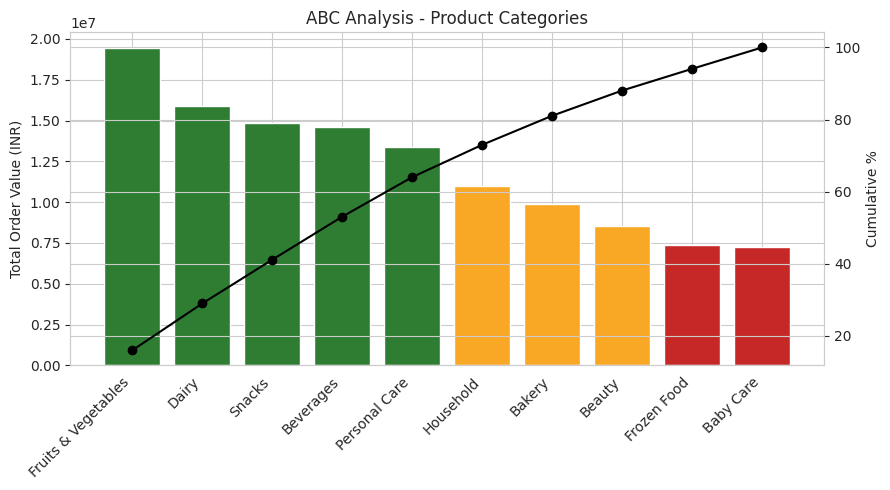

In [23]:
colors = category_value['ABC_Class'].map({'A':'#2e7d32', 'B':'#f9a825', 'C':'#c62828'})

fig, ax1 = plt.subplots(figsize=(9,5))
ax1.bar(category_value['Product Category'], category_value['Total_Value'], color=colors)
ax1.set_ylabel('Total Order Value (INR)')
plt.xticks(rotation=45, ha='right')

ax2 = ax1.twinx()
ax2.plot(category_value['Product Category'], category_value['cum_pct'], color='black', marker='o')
ax2.set_ylabel('Cumulative %')

plt.title('ABC Analysis - Product Categories')
plt.tight_layout()
plt.show()

In [24]:
category_value['ABC_Class'].value_counts()

ABC_Class
A    5
B    3
C    2
Name: count, dtype: int64

## 8. Summary

- Processed ~105K order records across Blinkit, JioMart and Swiggy Instamart, loaded from `ecommerce_delivery_data.csv`.
- ARIMA(2,1,2) gave a reasonable fit for daily order volume forecasting (used for the 14-day demand outlook).
- EOQ, Safety Stock and Reorder Point calculated per product category using the forecasted demand + a 95% service level.
- ABC analysis flagged the top categories (Class A) that drive ~70% of order value - these should get priority in inventory planning.

Next steps if I get more time: bring in actual holding/ordering cost numbers instead of the assumed ones, and try SARIMA to account for weekly seasonality more properly.